# COS802 Project — Housing Price Prediction
## Notebook 03: Baseline Models
Establish the naive mean-price benchmark, ordinary Linear Regression, and Ridge Regression baselines using the frozen five development folds. Compare original versus engineered features and raw versus `log1p(SalePrice)` targets. All MAE/RMSE results are reported on the original dollar scale. The held-out test set remains locked.


In [13]:
from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
from pathlib import Path
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Canonical reusable project code
PROJECT_DIR = Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import SEED, TARGET, IDENTIFIERS, DATA_FILE, PROCESSED_DIR, SPLITS_DIR, FIGURES_DIR
from src.features import (
    STRUCTURAL_NONE_COLS, ENGINEERED_FEATURES, apply_structural_absence,
    AmesFeatureEngineer, validate_engineered_features, validate_feature_alignment,
)
from src.preprocessing import ORDINAL_CATEGORY_MAP, build_preprocessor
from src.evaluation import regression_metrics

SEED=16153970
PROJECT_DIR=Path("/content/drive/MyDrive/MIT BIG DATA SCIENCE/COS802_PROJECT")
RAW_DIR=PROJECT_DIR/"data"/"raw"; PROCESSED_DIR=PROJECT_DIR/"data"/"processed"
SPLITS_DIR=PROJECT_DIR/"data"/"splits"; FIGURES_DIR=PROJECT_DIR/"figures"
df=pd.read_csv(RAW_DIR/"AmesHousing.txt",sep="\t")
split_membership=pd.read_csv(SPLITS_DIR/"train_test_split.csv")
cv_membership=pd.read_csv(SPLITS_DIR/"development_cv_folds.csv")


## 1. Restore the frozen development data
No test-set performance is calculated in this notebook.


In [15]:
TARGET="SalePrice"; IDENTIFIERS=["Order","PID"]
dev_idx=split_membership.loc[split_membership["split"]=="development","row_index"].astype(int).to_numpy()
test_idx=split_membership.loc[split_membership["split"]=="test","row_index"].astype(int).to_numpy()
dev_df=df.loc[dev_idx].copy()
X_dev_raw=dev_df.drop(columns=[TARGET]+IDENTIFIERS)
y_dev=dev_df[TARGET].astype(float).copy()
print("Development:",X_dev_raw.shape,"Locked test rows:",len(test_idx))


Development: (2344, 79) Locked test rows: 586


## 2. Reproduce Notebook 02 preprocessing
Definitions match Notebook 02 so transformations are learned separately within every training fold.


In [16]:
X_dev_engineered = AmesFeatureEngineer().fit_transform(X_dev_raw)
validate_engineered_features(X_dev_engineered)
print("Using canonical feature engineering from src.features")


Using canonical feature engineering from src.features


In [17]:
# Linear and Ridge models use scaled numeric predictors.
def linear_preprocessor(X):
    return build_preprocessor(X, scale_numeric=True)


## 3. Restore identical five-fold CV


In [18]:
row_to_pos={int(idx):pos for pos,idx in enumerate(dev_idx)}
folds=[]
for f in sorted(cv_membership["fold"].unique()):
    z=cv_membership[cv_membership["fold"]==f]
    tr=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="train","row_index"]])
    va=np.array([row_to_pos[int(r)] for r in z.loc[z.role=="validation","row_index"]])
    folds.append((tr,va))
    print(f"Fold {f}: train={len(tr)}, validation={len(va)}")


Fold 1: train=1875, validation=469
Fold 2: train=1875, validation=469
Fold 3: train=1875, validation=469
Fold 4: train=1875, validation=469
Fold 5: train=1876, validation=468


## 4. Evaluation functions
For log-target models, predictions are back-transformed with `expm1` before MAE, RMSE and R² are calculated. The same preprocessing and frozen folds are used for Linear and Ridge Regression.


In [19]:
def eval_mean(X,y):
    out=[]
    for f,(tr,va) in enumerate(folds,1):
        p=np.repeat(y.iloc[tr].mean(),len(va))
        out.append({"Experiment":"Naive mean","Fold":f,**regression_metrics(y.iloc[va],p)})
    return pd.DataFrame(out)

def eval_linear_model(X,y,label,model,log_target=False):
    out=[]
    for f,(tr,va) in enumerate(folds,1):
        pipe=Pipeline([
            ("preprocessor",linear_preprocessor(X.iloc[tr])),
            ("model",model)
        ])
        yt=np.log1p(y.iloc[tr]) if log_target else y.iloc[tr]
        pipe.fit(X.iloc[tr],yt)
        p=pipe.predict(X.iloc[va])
        if log_target:
            p=np.expm1(p)
        p=np.maximum(p,0)
        out.append({"Experiment":label,"Fold":f,**regression_metrics(y.iloc[va],p)})
    return pd.DataFrame(out)


## 5. Run baseline experiments
Ordinary Linear Regression provides the unregularised linear baseline. Ridge uses `alpha=1.0` as an untuned regularised linear baseline. Both are evaluated with original and engineered features on raw and log-transformed targets.


In [20]:
results=pd.concat([
 eval_mean(X_dev_raw,y_dev),

 eval_linear_model(X_dev_raw,y_dev,"Linear | Original | Raw",LinearRegression()),
 eval_linear_model(X_dev_raw,y_dev,"Linear | Original | Log",LinearRegression(),True),
 eval_linear_model(X_dev_engineered,y_dev,"Linear | Engineered | Raw",LinearRegression()),
 eval_linear_model(X_dev_engineered,y_dev,"Linear | Engineered | Log",LinearRegression(),True),

 eval_linear_model(X_dev_raw,y_dev,"Ridge | Original | Raw",Ridge(alpha=1.0)),
 eval_linear_model(X_dev_raw,y_dev,"Ridge | Original | Log",Ridge(alpha=1.0),True),
 eval_linear_model(X_dev_engineered,y_dev,"Ridge | Engineered | Raw",Ridge(alpha=1.0)),
 eval_linear_model(X_dev_engineered,y_dev,"Ridge | Engineered | Log",Ridge(alpha=1.0),True)
],ignore_index=True)
display(results.round(3))


,Experiment,Fold,MAE,RMSE,R2
0,Naive mean,1,59420.643,85375.598,-0.001
1,Naive mean,2,56919.083,74217.298,-0.000
2,Naive mean,3,60278.398,82241.490,-0.004
3,Naive mean,4,61317.215,85775.019,-0.003
4,Naive mean,5,53638.094,70349.532,-0.005
5,Linear | Original | Raw,1,17643.595,28213.287,0.891
6,Linear | Original | Raw,2,17298.273,34740.389,0.781
7,Linear | Original | Raw,3,17637.776,39309.168,0.771
8,Linear | Original | Raw,4,17938.170,27288.122,0.899
9,Linear | Original | Raw,5,16791.819,23832.350,0.885


## 6. Five-fold summary
Lower MAE/RMSE is better; higher R² is better.


In [21]:
summary=(results.groupby("Experiment").agg(
 MAE_mean=("MAE","mean"),MAE_sd=("MAE","std"),
 RMSE_mean=("RMSE","mean"),RMSE_sd=("RMSE","std"),
 R2_mean=("R2","mean"),R2_sd=("R2","std")).sort_values("RMSE_mean"))
display(summary.round(3))
results.to_csv(PROCESSED_DIR/"baseline_cv_fold_results.csv",index=False)
summary.to_csv(PROCESSED_DIR/"baseline_cv_summary.csv")


,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,R2_sd
Experiment,,,,,,
Ridge | Original | Raw,17547.111,704.914,30144.904,5817.114,0.851,0.056
Linear | Original | Raw,17461.926,437.767,30676.663,6233.560,0.845,0.064
Ridge | Engineered | Raw,16775.143,592.575,31251.606,7914.227,0.836,0.084
Linear | Engineered | Raw,16390.240,806.091,32093.542,10572.962,0.820,0.119
Ridge | Engineered | Log,15307.834,1100.416,39008.609,23026.087,0.694,0.331
Ridge | Original | Log,15378.057,1549.010,45713.551,34967.587,0.515,0.612
Linear | Engineered | Log,15169.799,1694.074,46506.380,36261.152,0.491,0.644
Linear | Original | Log,15366.660,2360.809,52753.968,46865.981,0.285,0.985
Naive mean,58314.687,3078.665,79591.788,6946.405,-0.003,0.002


## 7. Controlled feature-engineering comparison
For both Linear and Ridge Regression, original and engineered representations are compared under the same target definition and identical CV folds. Positive MAE/RMSE reduction means engineered features reduced error; positive ΔR² means improved explained variance.


In [22]:
def compare(model,target):
    o=f"{model} | Original | {target}"
    e=f"{model} | Engineered | {target}"
    a,b=summary.loc[o],summary.loc[e]
    return {
      "Model":model,"Target":target,
      "MAE_original":a.MAE_mean,"MAE_engineered":b.MAE_mean,
      "MAE_reduction_%":100*(a.MAE_mean-b.MAE_mean)/a.MAE_mean,
      "RMSE_original":a.RMSE_mean,"RMSE_engineered":b.RMSE_mean,
      "RMSE_reduction_%":100*(a.RMSE_mean-b.RMSE_mean)/a.RMSE_mean,
      "R2_original":a.R2_mean,"R2_engineered":b.R2_mean,
      "Delta_R2":b.R2_mean-a.R2_mean
    }

comparison=pd.DataFrame([
 compare("Linear","Raw"),
 compare("Linear","Log"),
 compare("Ridge","Raw"),
 compare("Ridge","Log")
])
display(comparison.round(4))
comparison.to_csv(PROCESSED_DIR/"linear_ridge_feature_engineering_comparison.csv",index=False)


,Model,Target,MAE_original,MAE_engineered,MAE_reduction_%,RMSE_original,RMSE_engineered,RMSE_reduction_%,R2_original,R2_engineered,Delta_R2
0,Linear,Raw,17461.9265,16390.2400,6.1373,30676.6633,32093.5416,-4.6187,0.8451,0.8196,-0.0254
1,Linear,Log,15366.6604,15169.7993,1.2811,52753.9678,46506.3798,11.8429,0.2851,0.4910,0.2059
2,Ridge,Raw,17547.1108,16775.1427,4.3994,30144.9044,31251.6059,-3.6713,0.8515,0.8359,-0.0156
3,Ridge,Log,15378.0569,15307.8339,0.4566,45713.5510,39008.6089,14.6673,0.5153,0.6942,0.1789


## 8. Baseline visualisations


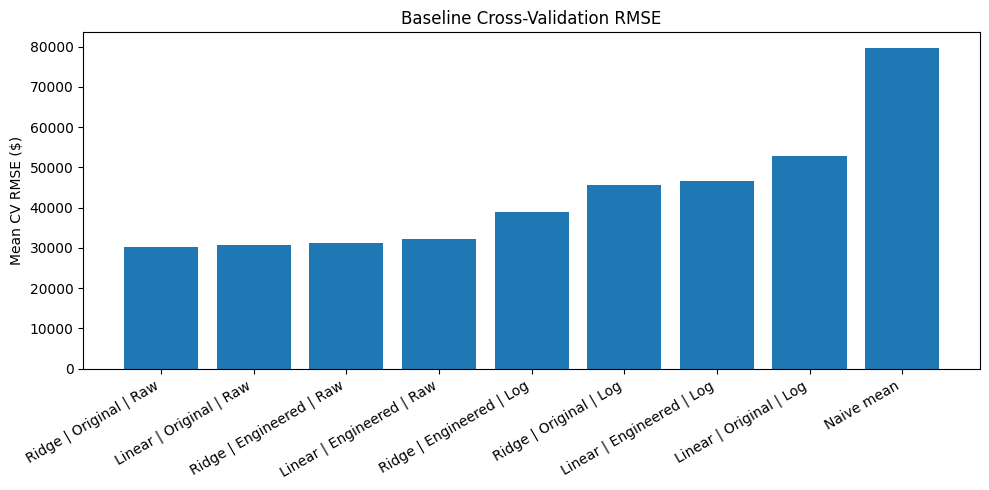

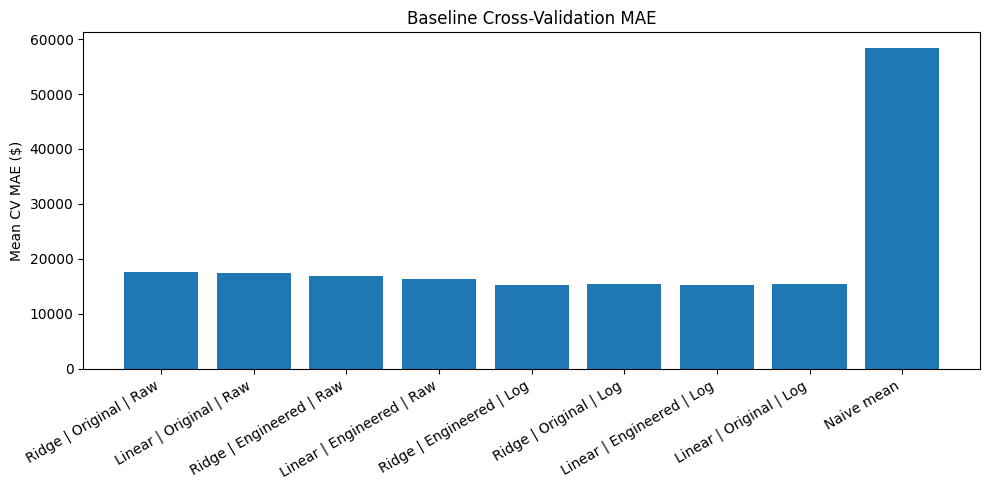

In [23]:
p=summary.reset_index()
for metric,label,name in [("RMSE_mean","Mean CV RMSE ($)","baseline_cv_rmse.png"),("MAE_mean","Mean CV MAE ($)","baseline_cv_mae.png")]:
    plt.figure(figsize=(10,5)); plt.bar(p["Experiment"],p[metric])
    plt.ylabel(label); plt.title("Baseline Cross-Validation "+metric.split("_")[0])
    plt.xticks(rotation=30,ha="right"); plt.tight_layout()
    plt.savefig(FIGURES_DIR/name,dpi=300,bbox_inches="tight"); plt.show()


## 9. Evidence summary


In [24]:
print("Lowest mean CV RMSE:",summary.RMSE_mean.idxmin())
print("Lowest mean CV MAE:",summary.MAE_mean.idxmin())
print("Highest mean CV R²:",summary.R2_mean.idxmax())
for _,r in comparison.iterrows():
    print(
        f'{r.Model} / {r.Target}: engineered vs original — '
        f'MAE reduction {r["MAE_reduction_%"]:.2f}%, '
        f'RMSE reduction {r["RMSE_reduction_%"]:.2f}%, '
        f'ΔR² {r.Delta_R2:.4f}'
    )


Lowest mean CV RMSE: Ridge | Original | Raw
Lowest mean CV MAE: Linear | Engineered | Log
Highest mean CV R²: Ridge | Original | Raw
Linear / Raw: engineered vs original — MAE reduction 6.14%, RMSE reduction -4.62%, ΔR² -0.0254
Linear / Log: engineered vs original — MAE reduction 1.28%, RMSE reduction 11.84%, ΔR² 0.2059
Ridge / Raw: engineered vs original — MAE reduction 4.40%, RMSE reduction -3.67%, ΔR² -0.0156
Ridge / Log: engineered vs original — MAE reduction 0.46%, RMSE reduction 14.67%, ΔR² 0.1789


## Notebook 03 Conclusions
Use the executed outputs above for the empirical conclusions rather than deciding them in advance.

This notebook establishes the naive mean-price benchmark and both approved linear baselines: ordinary Linear Regression and Ridge Regression. It also provides controlled original-versus-engineered and raw-versus-log target comparisons under identical five-fold development evaluation. The **586-property held-out test set remains untouched**.

### Next notebook
`04_model_comparison.ipynb` compares the linear baselines with Random Forest and XGBoost using development data only before final held-out testing.
